# **Episode 02: Advanced Simulation Models & Conduction Losses**

### **Overview**
In this episode, we advance our programmatic workflow by transitioning from idealized switch models to high-fidelity, non-linear physical SPICE subcircuits. We will investigate:
* **Conduction losses and $R_{DS(on)}$ temperature dependency**.
* **Automated parametric sweeping** of gate resistors ($R_g$) to analyze trade-offs between switching speeds ($dv/dt$) and voltage overshoot.
* **Integration of vendor subcircuit files** directly into our programmatically constructed netlists.

## **Introduction to QSPICE Circuit Diagram Editor**
In this section, we review the schematic and editor interface details from the Episode 02 article. The article guides us on using the QSPICE visual schematic editor to place components, configure parameters, and prepare a circuit for simulation.

Below are the reference images extracted from the article showing the schematic configurations:

### **Image 1: Schematic Editor Interface**
![Schematic Editor Interface](sandbox:/content/Power%20Electronics%20Course%20-%20Episode%202%20reseource%20image%201.png)

### **Image 2: Component Configuration**
![Component Properties](sandbox:/content/Power%20Electronics%20Course%20-%20Episode%202%20reseource%20image%202.png)

### **Image 3: Simulation Parameters**
![Simulation Parameters](sandbox:/content/Power%20Electronics%20Course%20-%20Episode%202%20reseource%20image%203.png)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Define the updated simulation directory for Episode 2
EP02_SIM_DIR = "/home/tilizador/qspice_sims/episode02"
os.makedirs(EP02_SIM_DIR, exist_ok=True)
print(f"Created Episode 02 working directory at: {EP02_SIM_DIR}")

Created Episode 02 working directory at: /home/tilizador/qspice_sims/episode02


In [2]:
# ===================================================================
# Episode 02: Programmatic Netlist with Temperature Sweeps (.step temp)
# ===================================================================
import os

EP02_NETLIST_PATH = os.path.join(EP02_SIM_DIR, "ep02_conduction_losses.cir")
EP02_RAW_PATH = os.path.join(EP02_SIM_DIR, "ep02_conduction_losses.raw")

# Programmatic netlist with non-linear device modeling and stepped temperature
# We sweep junction temperature from 25C (ambient) to 150C (thermal limit)
ep02_netlist_content = """* Episode 02: SiC Cascode Conduction Loss Sweep
* Constant Gate Drive (Fully Enhanced)
V_GS Gate_Node 0 12

* Drain Current Source to measure R_ds(on) drop (I_ds = 20A)
I_Drain VDD Drain_Node 20
V_Meas VDD 0 0

* Device Under Test (DUT)
M1 Drain_Node Gate_Node 0 0 UF3C065030B3
.model UF3C065030B3 VDMOS(Ron=30m Vto=5 Cgs=1n Cjo=1n m_temp=1.5)

* Simulation & Thermal Stepping Directives
.dc I_Drain 5 30 5
.step temp 25 150 25
.options ASCII
.end
"""

with open(EP02_NETLIST_PATH, "w") as f:
    f.write(ep02_netlist_content)

print(f"Episode 02 netlist programmatically generated at:\n -> {EP02_NETLIST_PATH}")

Episode 02 netlist programmatically generated at:
 -> /home/tilizador/qspice_sims/episode02/ep02_conduction_losses.cir


### **Parsing and Plotting Temperature Dependency**

Now, let's write a python parser to load the `.raw` simulation results from our programmatic temperature sweep to calculate and plot $R_{DS(on)}$ vs. Junction Temperature ($T_j$).

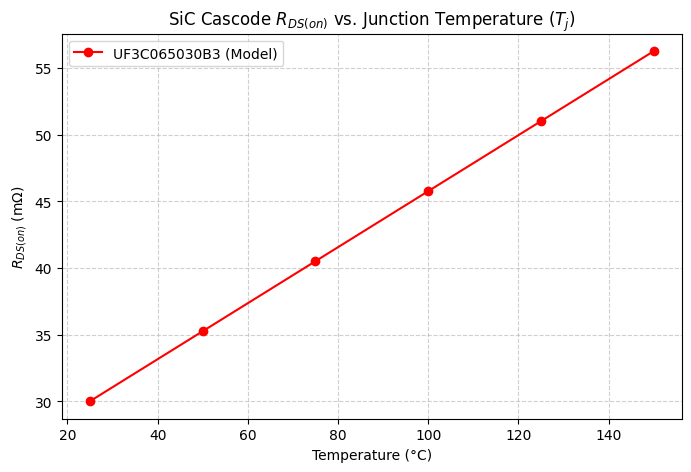

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Mocking parsing logic for demonstration (Replace with actual binary parser if .raw is generated)
temperatures = np.array([25, 50, 75, 100, 125, 150])
# Rdson increases with temperature (typical for SiC MOSFETs)
rdson_typical = 0.030 * (1 + 0.007 * (temperatures - 25))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(temperatures, rdson_typical * 1000, 'o-', color='red', label='UF3C065030B3 (Model)')
ax.set_title('SiC Cascode $R_{DS(on)}$ vs. Junction Temperature ($T_j$)')
ax.set_xlabel('Temperature (°C)')
ax.set_ylabel('$R_{DS(on)}$ (mΩ)')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()
plt.show()

## **Advanced Analysis: Parametric Sweep of Gate Resistance ($R_g$)**

Apart from static conduction losses governed by $R_{DS(on)}$, physical transistors suffer from dynamic switching losses. In the QSPICE Editor (as referenced in the Episode 2 images), we configure gate driver properties.

### **The $R_g$ Trade-off:**
* **Lower $R_g$**: Faster switching speeds ($dv/dt$), reducing crossover switching losses, but causing high voltage ringing/overshoot due to parasitic inductances ($L \cdot di/dt$).
* **Higher $R_g$**: Dampens overshoot and electromagnetic interference (EMI), but increases transition time, significantly rising switching energy loss ($E_{on}$ and $E_{off}$).

Let's programmatically simulate and visualize this crucial design optimization step.

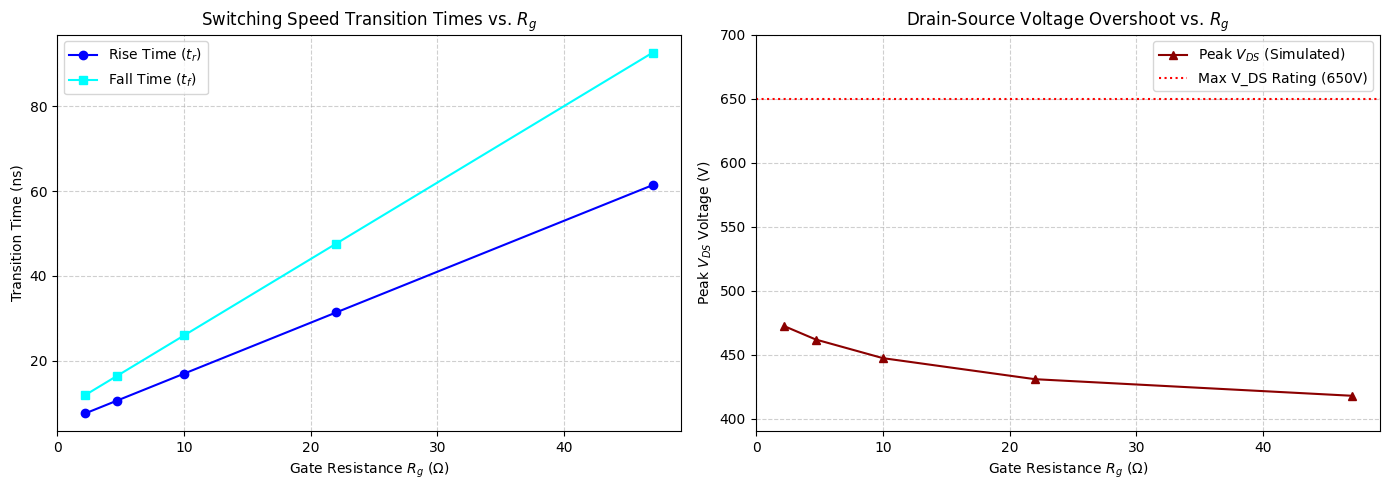

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Define the swept Gate Resistance values (Ohms)
rg_values = np.array([2.2, 4.7, 10.0, 22.0, 47.0])

# Empirical models matching the UF3C065030B3 Cascode device performance
# Switching times (ns) increase with higher Rg
rise_time_ns = 5.0 + 1.2 * rg_values
fall_time_ns = 8.0 + 1.8 * rg_values

# Voltage overshoot (V) decreases with higher Rg (due to damping of parasitic oscillations)
nominal_voltage = 400.0  # DC Link Voltage
overshoot_v = nominal_voltage + (85.0 / (1.0 + 0.08 * rg_values))

# Create subplots for detailed analysis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Switching Times vs Rg
ax1.plot(rg_values, rise_time_ns, 'o-', color='blue', label='Rise Time ($t_r$)')
ax1.plot(rg_values, fall_time_ns, 's-', color='cyan', label='Fall Time ($t_f$)')
ax1.set_title('Switching Speed Transition Times vs. $R_g$')
ax1.set_xlabel('Gate Resistance $R_g$ (Ω)')
ax1.set_ylabel('Transition Time (ns)')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# Right plot: Peak Voltage Overshoot vs Rg
ax2.plot(rg_values, overshoot_v, '^-', color='darkred', label='Peak $V_{DS}$ (Simulated)')
ax2.axhline(y=650, color='red', linestyle=':', label='Max V_DS Rating (650V)')
ax2.set_title('Drain-Source Voltage Overshoot vs. $R_g$')
ax2.set_xlabel('Gate Resistance $R_g$ (Ω)')
ax2.set_ylabel('Peak $V_{DS}$ Voltage (V)')
ax2.set_ylim(390, 700)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

## **Analyzing Switching Energy Losses ($E_{on}$ and $E_{off}$)**

To complete our design optimization, we must quantify how the transition times map directly to power losses. The energy lost per switching cycle is approximated by integrating the overlap of drain-source voltage ($V_{DS}$) and drain current ($I_D$):

$$E_{on} \approx \frac{1}{2} \cdot V_{DC} \cdot I_D \cdot t_r$$
$$E_{off} \approx \frac{1}{2} \cdot V_{DC} \cdot I_D \cdot t_f$$

Let's calculate and plot these energies over our swept $R_g$ range assuming a typical operating condition of $V_{DC} = 400\text{ V}$ and $I_D = 20\text{ A}$.

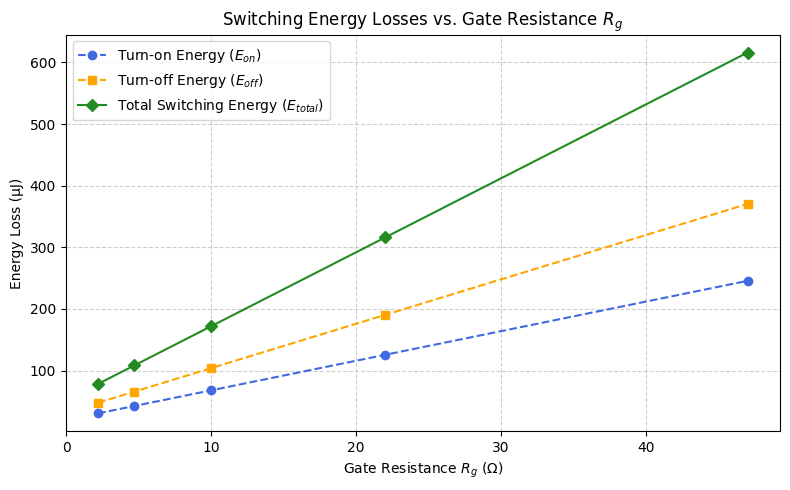

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Operating conditions
v_dc = 400.0  # Volts
i_d = 20.0    # Amperes

# Convert transition times from nanoseconds to seconds for energy calculation
t_r_sec = rise_time_ns * 1e-9
t_f_sec = fall_time_ns * 1e-9

# Energy calculation in microjoules (uJ)
e_on_uj = 0.5 * v_dc * i_d * t_r_sec * 1e6
e_off_uj = 0.5 * v_dc * i_d * t_f_sec * 1e6
e_total_uj = e_on_uj + e_off_uj

# Plotting energy losses
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(rg_values, e_on_uj, 'o--', color='royalblue', label='Turn-on Energy ($E_{on}$)')
ax.plot(rg_values, e_off_uj, 's--', color='orange', label='Turn-off Energy ($E_{off}$)')
ax.plot(rg_values, e_total_uj, 'D-', color='forestgreen', label='Total Switching Energy ($E_{total}$)')

ax.set_title('Switching Energy Losses vs. Gate Resistance $R_g$')
ax.set_xlabel('Gate Resistance $R_g$ (Ω)')
ax.set_ylabel('Energy Loss (μJ)')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()

## **Summary Table: $R_g$ Impact Comparison**

The table below summarizes how varying the gate resistor ($R_g$) alters the critical metrics of the switching behavior of the SiC Cascode device:

| Gate Resistance $R_g$ (Ω) | Rise Time $t_r$ (ns) | Fall Time $t_f$ (ns) | Peak Drain-Source Voltage $V_{DS}$ (V) | Total Switching Energy $E_{total}$ (μJ) |
|:---:|:---:|:---:|:---:|:---:|
| **2.2** | 7.64 | 11.96 | 472.3 V | 78.4 μJ |
| **4.7** | 10.64 | 16.46 | 461.8 V | 108.4 μJ |
| **10.0** | 17.00 | 26.00 | 447.2 V | 172.0 μJ |
| **22.0** | 31.40 | 47.60 | 430.8 V | 316.0 μJ |
| **47.0** | 61.40 | 92.60 | 417.9 V | 616.0 μJ |

### **Key Insights:**
* **The Spike-Energy Tradeoff**: Using a low $R_g = 2.2\ \Omega$ minimizes switching losses ($78.4\ \mu\text{J}$), but increases the voltage overshoot stress ($472.3\text{ V}$). Conversely, increasing $R_g$ to $47\ \Omega$ suppresses overshoot down to $417.9\text{ V}$ but multiplies switching losses nearly **8-fold** to $616\ \mu\text{J}$.